# Win at Gambling? - Understanding the Martingale Strategy

*Shayana Gurindapalli · Computational Probability · Oct 25, 2026*

Have you ever placed a bet? Do you want to? If you're ever planning on gambling, I have a betting strategy for you that technically always ends in profit!

<p align="center">
<img src="counting-money-im-rich.gif" width="300">
</p>


In this blog post, we will use a computer simulation to play rounds of roulette and answer the question: **Is the Martingale betting strategy actually profitable?**

## Rules of the Roulette

Roulette is one of the most popular gambling games one can partake in. It's quite simple: a roulette table has 38 evenly sized pockets that are placed on a wheel (this allows the pockets to spin). There are three colors of pockets: red (18 pockets), black (18 pockets), and green (2 pockets). Each pocket is numbered. Additionally, here is a roulette ball that spins in counter rotation. 

<p align="center">
<img src="roulette.jpg" width="300" style="border: 2px solid black;">
</p>

The rules of the game are easy: place a bet on where you think the roulette ball will land. Based on the betting game, this guess can vary; you can guess the color of the pocket, the number of the pocket, whether the ball lands on an odd or even number.

For this simulation, the size of the first bet will be $1 on black or red with additional winnings. More specifically, if you bet $1 and win, you get your bet back and additional winnings the size of our initial bet. In this scenario, our chance of winning (P(win)) is 18/38, or approximately 0.474

<!-- TODO: walk through ONE short example sequence (e.g. Black, Black, Red) in a small table,
showing why it *seems* to always end at +$1. -->

## The Martingale Strategy


Now, to elaborate on this "winning strategy"-- the Martingale strategy states that every time you lose a bet, you should double your next bet. This way, when you ultimately win, you will recover your loses and you would have a net win of your initial bet.

<p align="center">
<img src="martingale.jpg" width="300" style="border: 2px solid black;">
</p>

In application to this scenario, the first bet you would place would be $1. If you win, you get back your $1 and an additional $1 in winnings; the net gain would be $1. If you lose, you would place a second bet of $2. If you win the second bet, you would get back the $2 and an additional $2 in winnings (since this is the size of your bet); the net gain would be $1. 

Regardless of the losses, the win will always leave us $1 ahead of the bet placed.

| Play | Bet | Outcome | Result of this bet | Net earnings so far |
|------|-----|---------|--------------------|---------------------|
| 1 | $1 | Lose | −$1 | −$1 |
| 2 | $2 | Lose | −$2 | −$3 |
| 3 | $4 | Win | +$4 | +$1 |

## Purpose of Simulation

Instead of working out the math by hand, we can let a computer play roulette for us. It spins a virtual wheel using random numbers, follows the Martingale strategy, and records how much money we have after every spin. This way, we can get a realisitc look at the strategy's outcome without having to risk losses at a real casino.

## The rules of our simulated casino

Here are the rules for our casino. Each player starts out with a budget of $200, which we call **B**. When they reach **W**, $300, they stop betting. They also stop betting after **L** spins, in this case, 200. Like any real casino, our simulated casino also has a maximum bet limit, which in this case is $100 (**M**).  If the bet calls for $150, the player may only bet $100. 

It is also imperative to note that the player cannot wager more than what they have. Even if the maximum bet is $100, if the player has $50, that will be their maximum bet.

If players run out of money, it would be bankruptcy and the game ends there. 

| Parameter | Meaning | Starting value |
|-----------|---------|----------------|
| **B** | Starting budget | $200 |
| **W** | Stop when we reach this much money | $300 |
| **L** | Stop after this many spins | 200 |
| **M** | Casino's maximum bet | $100 |

To summarize, the game ends when the player (1) reaches **W**, (2) goes bankrupt, or (3) completes **L** spins.

## Building the simulation

The function `oneplay()` simulates one full visit to the casino. It takes our four rules (**B, W, L, M**) as inputs, and its first job is to set up a **ledger**, like a notebook where the player writes down their budget, their bets, and whether they won each spin. Then it repeats three steps until the visit is over:

1. **Place a bet (`wager`).** If the last spin was a win (or it's the very first spin), bet $1. Otherwise, double the last bet, but never bet more than the casino's maximum (M) or more than we have left; this follows the Martingale strategy.

2. **Spin the wheel (`spin`).** The computer flips a weighted coin that comes up "win" 18 out of 38 times, the same odds as betting on red or black.

3. **Update the budget and check whether to stop (`stop_rule`).** A win adds the bet to our budget and a loss subtracts it. Then we check whether we reached our goal W, ran out of spins (L), or went bankrupt. If none of those happened, the loop goes again.

When the visit ends, the function either hands back the whole ledger (so we can plot it) or a short summary: the final profit, how many spins it took, and how the visit ended.

In [16]:
import numpy as np
from itertools import groupby
import matplotlib.pyplot as plt
import pandas as pd

def oneplay(B=200, W=300, L=200, M=100, summary = True):

    # martingale
    def wager(ledger):
        if ledger["outcome"][-1] == 1:
            new_wager = 1
        else:
            new_wager = min(2*ledger["wager"][-1], M, ledger["budget"][-1])
        ledger["wager"].append(new_wager)

    def spin(ledger):
        spin = np.random.binomial(1, p = 18/38)
        ledger["outcome"].append(spin)

    def stop_rule(ledger):
        if ledger["outcome"][-1] == 1:
            ledger["budget"].append(ledger["budget"][-1] + ledger["wager"][-1])
        else:
            ledger["budget"].append(ledger["budget"][-1] - ledger["wager"][-1])
        
        if ledger["budget"][-1] >= W:
            outcome = 1
        elif len(ledger["budget"]) - 1 >= L:
            outcome = -1
        elif ledger["budget"][-1] <= 0:
            outcome = -2
        else:
            outcome = 0
        return outcome

    # ledger
    ledger = {"budget":[B, B], "wager":[0], "outcome":[1]}
    outcome = 0
    while outcome == 0:
        wager(ledger)
        spin(ledger)
        outcome = stop_rule(ledger)

    if summary == False:
        return ledger

    bad_luck = max([len(list(values)) for key, values in groupby(ledger["outcome"]) if key == 0])
        
    summary = {
          "B":B
        , "W":W
        , "L":L
        , "M":M
        , "outcome":outcome
        , "profit":ledger["budget"][-1] - B
        , "n_games":len(ledger["budget"]) - 1
        , "prop_red":np.mean(ledger["outcome"])
        , "bad_luck_streak": bad_luck
    }

    return summary

## A few visits to the casino

<!-- TODO: after the plot, describe what you see. How many went bankrupt? How many hit the goal?
How many ran out of spins? -->

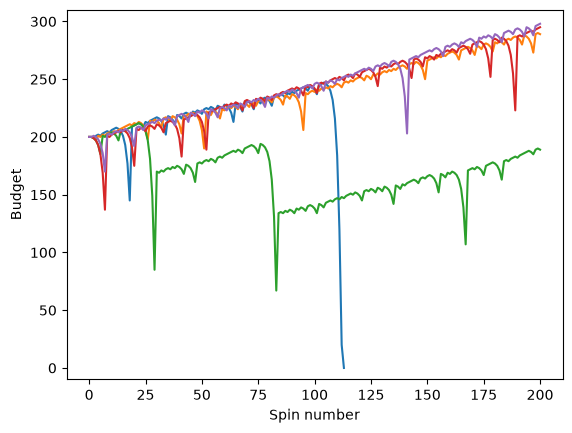

In [13]:
np.random.seed(101010)
plt.close()
for i in range(5):
    p1 = oneplay(summary = False)
    plt.plot(p1["budget"])
plt.ylim([-10, 310])
plt.xlabel("Spin number")
plt.ylabel("Budget")
plt.show()

Each line climbs slowly, about $1 at a time, and then drops sharply when a losing streak forces the bets to double again and again. Of our five visits, one went bankrupt (blue) after a long streak of bad luck, and the other four ran out of spins. Three of those ended just below the $300 goal, but none reached it. Winning $1 at a time is slow, so even the lucky visits struggled to climb $100 in 200 spins. The plot visibly shows that the purple, red, and orange players ended the closest to the final $300 goal. Interestingly, the green player shows a unique outcome with a mix of the blue and the other three. The outcome for the green player is very low as it never recovered from the big losses (around 25 and 75 spins). This plot demonstrates the risk in the Martingale strategy.

## Average profit over thousands of visits

<!-- TODO: explain why one visit isn't enough and why averaging over many visits helps.
Then interpret the number below. -->

In [11]:
R = 10000
A = [oneplay() for i in range(R)]
B = pd.DataFrame(A)
B.profit.mean().item()

-35.265

After simulating 10,000 visits (R), the average profit comes out to about **-$35**. This means, a player who starts with $200 and follows the Martingale strategy walks away with about $35 less than they started with. That seems to conflict with our plot, where most players were ahead. The explanation is that the strategy wins small amounts often, but loses big amounts rarely. A single bankruptcy costs a player their whole $200, which more than cancels out the dozens of $1 wins from visits that "went well".

## Does changing the rules change the answer?

<!-- TODO: say which parameter you're changing and why you picked it.
Sketch: M (the casino's max bet) is changed below, but you can swap in B, W, or L. -->

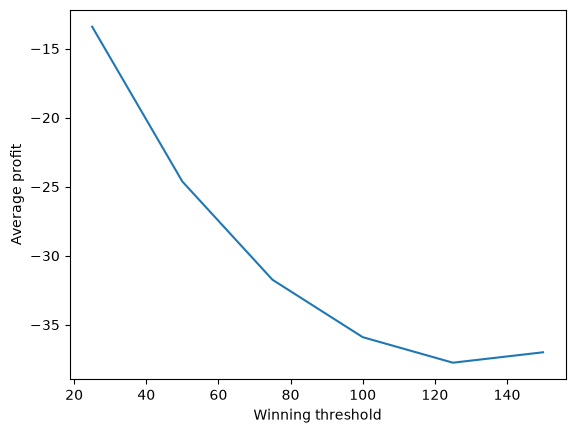

In [12]:
R = 40000
A = [oneplay(W = 200 + j) for j in [25, 50, 75, 100, 125, 150] for i in range(R)]
B = pd.DataFrame(A)
C = B.pivot_table(values="profit", index = "W").reset_index()
plt.close()
C.assign(walk_away_rule = C.W - 200).plot(x="walk_away_rule", y = "profit", legend = False)
plt.xlabel("Winning threshold")
plt.ylabel("Average profit")
plt.show()

This plot demonstrates what the average profit looks like when the winning threshole is changed; changing the winning threshold does have an impact on the average profit, but not nearly enough to make the strategy profitable. Here, each threshold is the profit a player needs above their $200 starting budget before walking away. When a player walks away after winning just $25, the average profit is about -$13. As the goal gets bigger, losses grow, and by $100 or more they level off around -$37. A smaller goal probably means fewer spins, so there's less time for a long losing streak to wipe the player out. But every threshold we tried ended in a negative average profit. No matter when the player decides to walk away, the casino comes out ahead on average.

## Take-home message

<!-- TODO: directly answer "Is the strategy actually profitable?"
Explain WHY it looks safe (lots of small wins) and why it isn't (rare, huge losses
that wipe out many small wins). End with something memorable. -->

Ultimately, I have to crush your dreams of getting rich with the Martingale strategy. **No, it is not profitable.** Across 10,000 simulated visits, the average player lost about $35 of their $200 budget.

So why did the strategy look so promising in our five-visit plot? Because it wins small amounts often, $1 at a time. But every loss doubles the next bet, so a long losing streak can quickly demand more money than the player has or the casino allows. One bankruptcy erases many small wins, and the two green pockets make things worse by tipping every spin slightly against the player. The winning-threshold plot shows that changing when you walk away changes how much you lose, but not whether you lose: every threshold we tried ended below zero.

The strategy is also slow. Even our luckiest players used nearly all 200 spins and still didn't reach the $300 goal. A strategy that "technically always ends in profit" is a slow way to lose money.